<div style="background:linear-gradient(135deg,#123524 0%,#1f5a45 45%,#2B5A82 100%);color:#fff;padding:40px 36px;border-radius:16px;font-family:system-ui,-apple-system,'Segoe UI',sans-serif">
  <div style="font-size:12px;letter-spacing:.16em;opacity:.75;text-transform:uppercase">43008 Reinforcement Learning &middot; Assignment 3 &middot; Team LMF</div>
  <div style="font-size:46px;font-weight:800;line-height:1.05;margin:12px 0 6px">Experiment: A2C</div>
  <div style="font-size:19px;opacity:.92">Advantage Actor-Critic on AgriFlight-RL, crop-row flight stabilisation</div>
  <div style="height:1px;background:rgba(255,255,255,.28);margin:24px 0 18px"></div>
  <div style="display:flex;flex-wrap:wrap;gap:36px">
    <div><div style="font-size:11px;letter-spacing:.12em;opacity:.7;text-transform:uppercase">Student</div><div style="font-size:20px;font-weight:600">Panzhao Li</div></div>
    <div><div style="font-size:11px;letter-spacing:.12em;opacity:.7;text-transform:uppercase">Student ID</div><div style="font-size:20px;font-weight:600">25399217</div></div>
    <div><div style="font-size:11px;letter-spacing:.12em;opacity:.7;text-transform:uppercase">Environment</div><div style="font-size:20px;font-weight:600">AgroDrone-v0 &middot; MuJoCo Skydio X2</div></div>
  </div>
</div>

### Contents

1. [Setup](#setup): environment, config, seeds, shared helpers
2. [Implementation](#implementation): the code
3. [Training](#training): run, curve, stability
4. [Evaluation](#evaluation): held-out seeds, baselines, difficulty levels
5. [Results](#results): table and plots
7. [Reproducibility](#contribution): who did what, versions, references


<a id="setup"></a>

## 1. Setup

**2.1 Bootstrap.** Finds the repo (or clones it), fetches the Skydio X2 model from the public MuJoCo Menagerie and installs any missing dependencies. Works on **AWS SageMaker**, **Google Colab** and a local Jupyter. Nothing to edit.


In [404]:
import os, sys, subprocess, time, importlib, importlib.util
NOTEBOOK_T0 = time.time()

IN_COLAB = "google.colab" in sys.modules
IN_SAGEMAKER = bool(
    os.environ.get("SAGEMAKER_INTERNAL_IMAGE_URI") or os.environ.get("SM_CURRENT_HOST")
    or os.path.isdir("/opt/ml/metadata") or os.path.expanduser("~") == "/home/sagemaker-user"
)
PLATFORM = "colab" if IN_COLAB else ("sagemaker" if IN_SAGEMAKER else "local")

REPO_URL = "github.com/Nelkit/agroflight-rl.git"   # private repo: needs a GitHub token (see 2.1)
BRANCH = "main"                                    # only used if this cell has to clone the repo itself
CLONE_DIR = "/content/agroflight-rl" if IN_COLAB else os.path.expanduser("~/agroflight-rl")

def run(cmd, cwd=None):
    subprocess.run(cmd, cwd=cwd, check=True)

def find_repo_root(start):
    p = os.path.abspath(start)
    while True:
        if os.path.isfile(os.path.join(p, "pyproject.toml")):
            return p
        parent = os.path.dirname(p)
        if parent == p:
            return None
        p = parent

# 1. Repo: this notebook's own clone, an existing clone in CLONE_DIR, or clone it now.
#    Search upwards from the notebook file (VS Code exposes its path) and from the kernel's
#    working directory, so a kernel started outside the repo still finds it.
_nb_file = globals().get("__vsc_ipynb_file__")   # set by VS Code, None elsewhere
_starts = ([os.path.dirname(_nb_file)] if _nb_file else []) + [os.getcwd()]
REPO = next((r for r in map(find_repo_root, _starts) if r), None)
if REPO is None and os.path.isfile(os.path.join(CLONE_DIR, "pyproject.toml")):
    REPO = CLONE_DIR
if REPO is None:
    token = os.environ.get("GITHUB_TOKEN")
    if not token and IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token and PLATFORM == "local":
        # Never prompt on a local machine: in VS Code the prompt is easy to miss and the cell looks hung.
        raise RuntimeError(
            f"agroflight-rl repo not found from {os.getcwd()}. Open this notebook from inside your "
            f"clone and restart the kernel, or set GITHUB_TOKEN to let this cell clone it into {CLONE_DIR}.")
    if not token:
        from getpass import getpass
        token = getpass("GitHub token for the private repo (hidden, not stored): ").strip()
    if not token:
        raise RuntimeError("No GitHub token given, so the private repo cannot be cloned. See 2.1.")
    # GIT_TERMINAL_PROMPT=0: a wrong token fails straight away instead of waiting for a password.
    subprocess.run(["git", "clone", "--quiet", "--branch", BRANCH, f"https://{token}@{REPO_URL}", CLONE_DIR],
                   check=True, env={**os.environ, "GIT_TERMINAL_PROMPT": "0"})
    run(["git", "remote", "set-url", "origin", "https://" + REPO_URL], cwd=CLONE_DIR)  # drop the token
    del token
    REPO = CLONE_DIR
os.chdir(REPO)

# 2. Drone model: Skydio X2 from the public google-deepmind/mujoco_menagerie (sparse clone, a few MB).
DRONE_XML = os.path.join(REPO, "mujoco_menagerie", "skydio_x2", "x2.xml")
if not os.path.isfile(DRONE_XML):
    if not os.path.isdir("mujoco_menagerie"):
        run(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse",
             "https://github.com/google-deepmind/mujoco_menagerie.git", "mujoco_menagerie"])
    run(["git", "sparse-checkout", "set", "skydio_x2"], cwd="mujoco_menagerie")
os.environ["AGRO_DRONE_XML"] = DRONE_XML

# 3. Dependencies: install the project (+ torch, matplotlib, pandas) only if something is missing.
if any(importlib.util.find_spec(m) is None for m in ("mujoco", "gymnasium", "torch", "matplotlib", "pandas")):
    run([sys.executable, "-m", "pip", "install", "-q", "-e", ".[train]"])
    importlib.invalidate_caches()
sys.path.insert(0, os.path.join(REPO, "src"))
import mujoco, gymnasium   # also used by the reproducibility cell in Section 9

_head = subprocess.run(["git", "log", "-1", "--format=%h (%ad)", "--date=short"], cwd=REPO,
                       capture_output=True, text=True).stdout.strip()
_branch = subprocess.run(["git", "rev-parse", "--abbrev-ref", "HEAD"], cwd=REPO,
                         capture_output=True, text=True).stdout.strip()
print("platform:", PLATFORM)
print("repo    :", REPO, "| branch", _branch, "| commit", _head)
print("model   :", DRONE_XML)

platform: local
repo    : d:\2026\RL\A3\agroflight-rl | branch panzhao/a2c-partc-results | commit 08f341b (2026-10-23)
model   : d:\2026\RL\A3\agroflight-rl\mujoco_menagerie\skydio_x2\x2.xml


**2.2 Experiment config and seeds.** Training seeds start at 0. Evaluation seeds start at 1000, so they are held out from training.

In [405]:
import random
import numpy as np
import torch

EXPERIMENT = dict(
    algorithm="A2C",
    student_name="Panzhao Li",
    student_id="25399217",
    env_id="AgroDrone-v0",
    train_seed=2,
    eval_seeds=list(range(1000, 1020)),
    level=4,   # start at L0; move up only when it works
)
BACKUP_TO_DRIVE = False   # set True in Colab to copy results and checkpoints to Google Drive (survives the runtime)

HPARAMS = dict(
    total_timesteps=1_000_000, 
    learning_rate=1e-4,
    gamma=0.99,
    n_steps=5,
    vf_coef=0.5,
    ent_coef=0.00,
    hidden=(64, 64),
    max_grad_norm=0.5,
    initial_log_std=-2.3
)

CHECKPOINT_CONFIG = dict(
    interval=100_000,
    best_window=5,
    best_min_episodes=5,
)

random.seed(EXPERIMENT["train_seed"])
np.random.seed(EXPERIMENT["train_seed"])
torch.manual_seed(EXPERIMENT["train_seed"])
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device 1:", DEVICE)
print("torch  :", torch.__version__, "| cuda:", torch.version.cuda, "| cudnn:", torch.backends.cudnn.version())

device 1: cpu
torch  : 2.14.0+cpu | cuda: None | cudnn: None


**2.3 Shared, identical in all three notebooks. Do not edit.** Results file schema (so one comparison notebook can read all three), checkpoint save and load (the viewer loads these), Drive backup, and the learning-curve plot.

In [406]:
import json, datetime, subprocess, shutil
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

RESULTS_DIR = os.path.join(REPO, "results")
CHECKPOINT_DIR = os.path.join(REPO, "checkpoints")

def git_commit():
    try:
        return subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], cwd=REPO, text=True).strip()
    except Exception:
        return None

def new_results():
    return dict(
        schema=1,
        algorithm=EXPERIMENT["algorithm"],
        student=dict(name=EXPERIMENT["student_name"], id=EXPERIMENT["student_id"]),
        env_id=EXPERIMENT["env_id"],
        git_commit=git_commit(),
        created=datetime.datetime.now().isoformat(timespec="seconds"),
        hparams=HPARAMS,
        training=dict(train_seed=EXPERIMENT["train_seed"], total_timesteps=None, wall_clock_s=None,
                      best_checkpoint=None, curve=[]),   # curve: list of {"timesteps": int, "mean_return": float}
        evaluation=dict(eval_seeds=EXPERIMENT["eval_seeds"], baselines={}, levels={}),
    )

def save_results(results):
    os.makedirs(RESULTS_DIR, exist_ok=True)

    training = results["training"]
    filename = (
        f"{results['algorithm'].lower()}_"
        f"{results['student']['id']}_"
        f"L{training['level']}_"
        f"seed{training['train_seed']}_"
        f"{training['run_id']}.json"
    )
    path = os.path.join(RESULTS_DIR, filename)

    with open(path, "w", encoding="utf-8") as f:
        json.dump(results, f, indent=2, ensure_ascii=False)

    return path

def save_checkpoint(model, obs_dim, act_dim, tag="best", *, timesteps):
    os.makedirs(CHECKPOINT_DIR, exist_ok=True)

    path = os.path.join(
        CHECKPOINT_DIR,
        f"{EXPERIMENT['algorithm'].lower()}_"
        f"{EXPERIMENT['student_id']}_{tag}.pt"
    )

    torch.save(
        dict(
            algorithm=EXPERIMENT["algorithm"],
            student_id=EXPERIMENT["student_id"],
            hparams=dict(HPARAMS),
            obs_dim=obs_dim,
            act_dim=act_dim,
            state_dict=model.state_dict(),
            level=int(EXPERIMENT["level"]),
            train_seed=int(EXPERIMENT["train_seed"]),
            timesteps=int(timesteps),
            checkpoint_config=dict(CHECKPOINT_CONFIG),
        ),
        path,
    )
    return path

def load_checkpoint(model, tag="best"):
    path = os.path.join(CHECKPOINT_DIR, f"{EXPERIMENT['algorithm'].lower()}_{EXPERIMENT['student_id']}_{tag}.pt")
    ckpt = torch.load(path, map_location="cpu")
    model.load_state_dict(ckpt["state_dict"])
    return ckpt

def backup_to_drive(dirs):
    if not IN_COLAB:
        print("Not in Colab: nothing to back up.")
        return
    from google.colab import drive
    drive.mount("/content/drive")
    dest = "/content/drive/MyDrive/agroflight"
    os.makedirs(dest, exist_ok=True)
    for d in dirs:
        if os.path.isdir(d):
            shutil.copytree(d, os.path.join(dest, os.path.basename(d)), dirs_exist_ok=True)
    print("backed up to", dest)

def plot_learning_curve(curve, window=10):
    xs = [p["timesteps"] for p in curve]
    ys = np.array([p["mean_return"] for p in curve], dtype=float)
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.plot(xs, ys, alpha=0.35, label="mean return")
    if len(ys) >= window:
        smooth = np.convolve(ys, np.ones(window) / window, mode="valid")
        ax.plot(xs[window - 1:], smooth, linewidth=2, label=f"moving average ({window})")
    ax.set_xlabel("environment steps")
    ax.set_ylabel("episode return")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.show()

RESULTS = new_results()

**2.4 Environment check.** One reset and one random step, to confirm the model loads.

In [407]:
import gymnasium as gym
import agroflight.envs
from agroflight.envs import ENV_ID

env = gym.make(ENV_ID, level=EXPERIMENT["level"])
obs, _ = env.reset(seed=EXPERIMENT["train_seed"])
print("observation:", env.observation_space.shape, "| action:", env.action_space.shape)
obs, r, terminated, truncated, info = env.step(env.action_space.sample())
print("one random step -> reward", round(r, 3), "| crashed:", info["crashed"])
env.close()

observation: (14,) | action: (4,)
one random step -> reward -0.019 | crashed: False


<a id="implementation"></a>

## 2. Implementation

Write A2C directly in PyTorch, following the subject's policy-gradient content. Keep the Gaussian policy head the same shape as the other two notebooks so the comparison stays fair.

4.1 Imolementation

In [ ]:
import torch
import torch.nn as nn
from torch.distributions import Normal

def layer_init(layer, std=np.sqrt(2), bias_const=0.0):
    torch.nn.init.orthogonal_(layer.weight, std)
    torch.nn.init.constant_(layer.bias, bias_const)
    return layer

class ActorCritic(nn.Module):
    """obs -> Gaussian action distribution (actor) and obs -> value (critic)."""
    def __init__(self, obs_dim, act_dim, hidden=HPARAMS["hidden"]):
        super().__init__()
        # actor mean network + learnable log_std, and a critic network
        h1, h2 = hidden
        # ---- Actor network ----
        self.actor_mean = nn.Sequential(
            layer_init(nn.Linear(obs_dim, h1)), nn.Tanh(),
            layer_init(nn.Linear(h1, h2)),      nn.Tanh(),
            layer_init(nn.Linear(h2, act_dim), std=0.01),
        )

        # ---- Critic network ----
        self.critic = nn.Sequential(
            layer_init(nn.Linear(obs_dim, h1)), nn.Tanh(),
            layer_init(nn.Linear(h1, h2)),      nn.Tanh(),
            layer_init(nn.Linear(h2, 1), std=1.0),
        )

        self.log_std = nn.Parameter(
            torch.full((1, act_dim), HPARAMS["initial_log_std"])
        )


    def forward(self, obs):
        # return (action distribution, value)
        action_mean = self.actor_mean(obs)
        value = self.critic(obs)
        action_std = torch.exp(self.log_std)

        return Normal(action_mean, action_std), value

def compute_advantages(rewards, values, dones, next_value, gamma):
    #  n-step returns and advantages
    values = values.detach()
    next_value = next_value.detach()

    return_targets = []
    advantages = []
    R = next_value
    T = len(rewards)
    for i in reversed(range(T)):
        if dones[i]:
            R = rewards[i]
        else:
            R = rewards[i] + gamma * R
        return_targets.append(R)
        advantages.append(R - values[i])
    return_targets.reverse()
    advantages.reverse()
    return torch.stack(return_targets), torch.stack(advantages)


def a2c_update(model, optimizer, batch):
    # policy loss + value loss + entropy bonus, one optimiser step
    obs = batch["obs"]                 # (T, 14)
    actions = batch["actions"]         # (T, 4)
    returns = batch["returns"]         # (T,)
    advantages = batch["advantages"]   # (T,)
    
    dist, value = model(obs)
    value = value.squeeze(-1)  # (T,)
    
    log_probs = dist.log_prob(actions).sum(dim=-1)  # (T,)
    entropy = dist.entropy().sum(dim=-1)  # (T,)

    policy_loss = -(log_probs * advantages.detach()).mean()
    value_loss = 0.5 * (returns.detach() - value).pow(2).mean()
    entropy_bonus = -HPARAMS["ent_coef"] * entropy.mean()
    loss = policy_loss + HPARAMS["vf_coef"] * value_loss + entropy_bonus

    optimizer.zero_grad()
    loss.backward()
    # gradient clipping
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=HPARAMS["max_grad_norm"])
    optimizer.step()

    return dict(policy_loss=policy_loss.item(), value_loss=value_loss.item(), entropy=entropy.mean().item(), total_loss=loss.item())


4.2 check part

In [409]:
# # check that the model can be instantiated and a forward pass works
# obs_dim = env.observation_space.shape[0]
# act_dim = env.action_space.shape[0]
# print("obs_dim:", obs_dim, "act_dim:", act_dim)
# model = ActorCritic(obs_dim, act_dim)
# print("model parameters:", sum(p.numel() for p in model.parameters()))
# # test_obs = torch.zeros(1, obs_dim)  # dummy input for testing
# test_obs = torch.as_tensor(obs, dtype=torch.float32).unsqueeze(0)  # use the first observation from the environment
# dist, value = model(test_obs)
# print("test forward pass -> action distribution shape:", dist.mean.shape, "| value shape", value.shape)
# print("action mean", dist.mean.detach().numpy(), "| value", value.item())
# print("action std", dist.stddev)
# action = dist.sample()
# print("action sample", action)

# env_action = action.squeeze(0)
# print("action shape:", action.shape, "| env_action shape:", env_action.shape, "| env_action dtype:", env_action.dtype)
# action_array = env_action.numpy()
# print("action array", action_array)

In [410]:
# # check that the environment can be created and reset
# check_env = gym.make(ENV_ID, level = 0)
# check_obs, reset_info = check_env.reset(seed=EXPERIMENT["train_seed"])
# print(check_obs.shape)

In [411]:
# # check that the model can do a forward pass and sample an action, and that the environment can step with that action
# check_input = torch.as_tensor(check_obs, dtype=torch.float32).unsqueeze(0)  
# check_dist, check_value = model(check_input)
# print("check forward pass -> action distribution shape:", check_dist.mean.shape, "| value shape", check_value.shape)

# check_action = check_dist.sample()
# print("check action sample", check_action)
# check_action_array = check_action.squeeze(0).numpy()
# print("check action array", check_action_array)

# check_env_step_obs, check_r, check_terminated, check_truncated, check_info = check_env.step(check_action_array)
# print("check environment step -> observation shape:", check_env_step_obs.shape)
# print("check reward:", check_r)
# print("check terminated:", check_terminated)
# print("check truncated:", check_truncated)
# print("check info:", check_info)

# check_env.close()

In [412]:
# # check that the compute_advantages function works as expected
# check_compute_advantages = compute_advantages([1, 2], [8, 9], [False, True], next_value= 10, gamma=0.90)

# print("check compute_advantages -> return_targets:", check_compute_advantages[0])
# print("check compute_advantages -> advantages:", check_compute_advantages[1])

# scalar_value = check_value.squeeze()
# print("check scalar value:", scalar_value.shape)

In [413]:
# # check compute advantages 
# test_data = {
#     "rewards": torch.tensor([1.0, 2.0]),
#     "values": torch.tensor([8.0, 9.0], requires_grad=True),
#     "dones": [False, True],
#     "next_value": torch.tensor(10.0, requires_grad=True),
#     "gamma": 0.90
# }
# computed_return_targets, computed_advantages = compute_advantages(
#     test_data["rewards"], test_data["values"], test_data["dones"], test_data["next_value"], test_data["gamma"]
# )
# print("Computed return targets:", computed_return_targets)
# print("Computed advantages:", computed_advantages)
# print("Computed return targets shape:", computed_return_targets.shape)
# print("Computed advantages shape:", computed_advantages.shape)
# print("Computed return targets requires_grad:", computed_return_targets.requires_grad)
# print("Computed advantages requires_grad:", computed_advantages.requires_grad)

In [414]:
# # check that the a2c_update function works as expected
# update_check_model = ActorCritic(obs_dim, act_dim)
# update_check_model.to(DEVICE)
# update_check_optimizer = torch.optim.Adam(update_check_model.parameters(), lr=HPARAMS["learning_rate"])
# params_before = [p.detach().clone() for p in update_check_model.parameters()]

# update_check_obs = torch.randn(2, obs_dim).to(DEVICE)  # batch of 2 observations
# update_check_dist, update_check_value = update_check_model(update_check_obs)
# update_check_actions = update_check_dist.sample()  
# update_check_value = update_check_value.squeeze(-1)  # (T,)
# update_check_returns = torch.randn(2).to(DEVICE)  # batch of 2 returns
# update_check_advantages = update_check_returns - update_check_value.detach()  # simple advantage estimate

# update_check_batch = {
#     "obs": update_check_obs,
#     "actions": update_check_actions,
#     "returns": update_check_returns,
#     "advantages": update_check_advantages
# }
# update_check_stats = a2c_update(update_check_model, update_check_optimizer, update_check_batch)
# print("Update check stats:", update_check_stats)

# for before, after in zip(params_before, update_check_model.parameters()):
#     diff = (after.detach() - before).abs().sum().item()
#     print("Parameter change sum:", diff)

<a id="training"></a>

## 3. Training

Training 2 for 200K, L0, Training seed 0, evaluation seed 1000-1019, crash_penalty=300, save in checkpoint_200000_L0(1).json & a2c_run2

PartE: Training for 1m L1-L4

In [ ]:
# training loop for A2C.
# After every N steps append a point to the curve, for example:
# RESULTS["training"]["curve"].append({"timesteps": global_step, "mean_return": mean_episode_return})
# When finished, set RESULTS["training"]["total_timesteps"] and RESULTS["training"]["wall_clock_s"].
#
# Keep the best model by TRAINING-time return, never by the held-out evaluation seeds:
# RESULTS["training"]["best_checkpoint"] = save_checkpoint(model, obs_dim=14, act_dim=4, tag="best")
import time

training_start = time.perf_counter()
train_env = gym.make(ENV_ID, level=EXPERIMENT["level"], reward_config={"crash_penalty": 300.0}) 
print(train_env.unwrapped.reward_config.crash_penalty)

obs_dim, act_dim = train_env.observation_space.shape[0], train_env.action_space.shape[0]

reset_training_env = train_env.reset(seed=EXPERIMENT["train_seed"])
train_obs = reset_training_env[0]
torch.manual_seed(EXPERIMENT["train_seed"])
train_model = ActorCritic(obs_dim, act_dim).to(DEVICE)
train_optimizer = torch.optim.Adam(train_model.parameters(), lr=HPARAMS["learning_rate"])

global_step = 0
episode_return = 0.0
episode_returns = []

# independent result record of each time
RESULTS = new_results()

# Levels, seeds, running times jointly used to distinguish different trainings, avoid overwriting old files.
run_id = datetime.datetime.now().strftime("%Y%m%d_%H%M%S_%f")
run_prefix = (
    f"checkpoint_{HPARAMS['total_timesteps']}_"
    f"Seed_{EXPERIMENT['train_seed']}_"
    f"Level{EXPERIMENT['level']}_{run_id}"
)

next_checkpoint_step = CHECKPOINT_CONFIG["interval"]
best_mean_return = -float("inf")
checkpoint_records = []

RESULTS["training"].update(
    run_id=run_id,
    level=int(EXPERIMENT["level"]),
    checkpoint_config=dict(CHECKPOINT_CONFIG),
    checkpoints=checkpoint_records,
    best_checkpoint=None,
    final_checkpoint=None,
    episode_returns=[],
)

def record_checkpoint(role, *, planned_timesteps=None,
                      selection_mean_return=None):
    tag = f"{run_prefix}_{role}"

    path = save_checkpoint(
        train_model,
        obs_dim=obs_dim,
        act_dim=act_dim,
        tag=tag,
        timesteps=global_step,
    )

    record = dict(
        role=role,
        tag=tag,
        path=path,
        timesteps=int(global_step),
        planned_timesteps=planned_timesteps,
        selection_mean_return=selection_mean_return,
    )

    if role == "best":
        checkpoint_records[:] = [
            item for item in checkpoint_records
            if item["role"] != "best"
        ]

    checkpoint_records.append(record)
    return record

# Training loop
check_budget  = HPARAMS["total_timesteps"]
while global_step < check_budget:
    rollout_obs = []
    rollout_actions = []
    rollout_rewards = []
    rollout_values = []
    rollout_terminated = []

    for step in range(min(HPARAMS["n_steps"], check_budget - global_step)):
        train_obs_tensor = torch.as_tensor(train_obs, dtype=torch.float32).unsqueeze(0).to(DEVICE)

        with torch.no_grad():
            dist, value = train_model(train_obs_tensor)

        action = dist.sample()
        action_array = action.squeeze(0).cpu().numpy()

        next_obs, reward, terminated, truncated, info = train_env.step(action_array)
        rollout_obs.append(train_obs_tensor.squeeze(0).to(DEVICE))
        rollout_actions.append(action.squeeze(0).to(DEVICE))
        rollout_rewards.append(torch.tensor(reward, dtype=torch.float32).to(DEVICE))
        rollout_values.append(value.squeeze())
        rollout_terminated.append(terminated)

        global_step += 1
        episode_return += reward
        train_obs = next_obs

        if terminated or truncated:
            break  # Exit the loop if the episode is done
            # reset_training_env = train_env.reset()
            # train_obs = reset_training_env[0]
            # print(f"Episode finished. Total return: {episode_return}")
            # episode_return = 0.0



    if terminated:
        next_value = torch.tensor(0.0, dtype=torch.float32).to(DEVICE)
    else:
        with torch.no_grad():
            next_value = train_model(torch.as_tensor(train_obs, dtype=torch.float32).unsqueeze(0).to(DEVICE))[1].squeeze()

    rewards_tensor = torch.stack(rollout_rewards)
    values_tensor = torch.stack(rollout_values)
    return_targets, advantages = compute_advantages(rewards_tensor, values_tensor, rollout_terminated, next_value, HPARAMS["gamma"])
    # print("Return targets:", return_targets, "shape:", return_targets.shape, "requires_grad:", return_targets.requires_grad)
    # print("Advantages:", advantages, "shape:", advantages.shape, "requires_grad:", advantages.requires_grad)

    train_batch = {
        "obs": torch.stack(rollout_obs),
        "actions": torch.stack(rollout_actions),
        "returns": return_targets,
        "advantages": advantages
    }
    train_stats = a2c_update(train_model, train_optimizer, train_batch)
    # print("Training stats:", train_stats)

    while (global_step >= next_checkpoint_step and next_checkpoint_step < check_budget):
        
        if global_step < check_budget:
            role = f"step_{next_checkpoint_step // 1000:04d}k"

            record_checkpoint(role, planned_timesteps=int(next_checkpoint_step),)

        next_checkpoint_step += CHECKPOINT_CONFIG["interval"]

    if terminated or truncated:
        episode_returns.append(episode_return)

        RESULTS["training"]["episode_returns"].append(dict(timesteps=int(global_step), episode_return=float(episode_return)))

        if len(episode_returns) >= CHECKPOINT_CONFIG["best_min_episodes"]:
            selection_mean_return = float(np.mean(episode_returns[-CHECKPOINT_CONFIG["best_window"]:]))

            if selection_mean_return > best_mean_return:
                best_mean_return = selection_mean_return

                best_record = record_checkpoint("best",selection_mean_return=selection_mean_return)

                RESULTS["training"]["best_checkpoint"] = best_record["path"]

        timestep = global_step
        mean_episode_return = np.mean(episode_returns[-20:])  # mean of last 20 episodes
        RESULTS["training"]["curve"].append({"timesteps": timestep, "mean_return": mean_episode_return})
        # print(terminated, truncated)
        # print(f"Episode finished. Total return: {episode_return}")
        train_obs, train_info = train_env.reset()
        episode_return = 0.0

print("Training finished. Total steps:", global_step)
print("Final training stats:", train_stats)
training_elapsed = time.perf_counter() - training_start
print("Training time (seconds):", training_elapsed)
print("Completed episodes:", len(episode_returns))
RESULTS["training"]["total_timesteps"] = global_step
RESULTS["training"]["wall_clock_s"] = training_elapsed
final_record = record_checkpoint("final")
RESULTS["training"]["final_checkpoint"] = final_record["path"]

train_env.close()

print("Saved final:", final_record["path"])
print("Actual timesteps:", final_record["timesteps"])

print("Saved training results:", save_results(RESULTS))

300.0
Training finished. Total steps: 1000000
Final training stats: {'policy_loss': -0.9249418377876282, 'value_loss': 0.03262236714363098, 'entropy': -2.647047519683838, 'total_loss': -0.9086306691169739}
Training time (seconds): 851.2769950000002
Completed episodes: 4821
Saved final: d:\2026\RL\A3\agroflight-rl\checkpoints\a2c_25399217_checkpoint_1000000_Seed_2_Level4_20261023_190358_675482_final.pt
Actual timesteps: 1000000
Saved training results: d:\2026\RL\A3\agroflight-rl\results\a2c_25399217_L4_seed2_20261023_190358_675482.json


In [416]:
# For_short_test = save_checkpoint(train_model, obs_dim=obs_dim, act_dim=act_dim, tag=f"checkpoint_{check_budget}_Seed_{EXPERIMENT['train_seed']}_Level{EXPERIMENT['level']}(1)")
# print("Saved checkpoint for short test:", For_short_test)

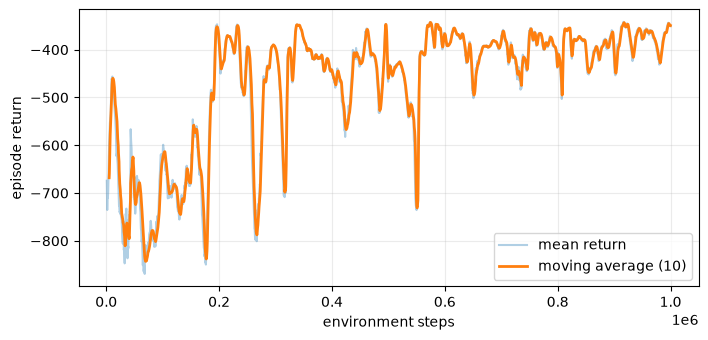

In [417]:
if RESULTS["training"]["curve"]:
    plot_learning_curve(RESULTS["training"]["curve"])
else:
    print("No training run recorded yet.")

<a id="evaluation"></a>

## 4. Evaluation

Every policy is evaluated on the same held-out seeds (1000 to 1019) with exploration disabled. The two hand-coded baselines run at this notebook's level (`EXPERIMENT["level"]`, L0 by default); re-run them if the environment changes.

6.1 restore check

In [418]:
# # restore the model for evaluation
# diagnostic_env = gym.make(ENV_ID, level=0, reward_config={"crash_penalty": 300.0})

# obs_dim = diagnostic_env.observation_space.shape[0]
# act_dim = diagnostic_env.action_space.shape[0]

# train_model = ActorCritic(obs_dim, act_dim).to(DEVICE)
# load_checkpoint(train_model, tag="checkpoint_200000_Level0(1)")
# train_model.eval()

In [419]:
# check that the model can do a forward pass and sample an action, and that the environment can step with that action
from agroflight.evaluation.evaluate_policy import evaluate
from agroflight.baselines import altitude_hold_action, random_action

eval_env = gym.make(ENV_ID, level=EXPERIMENT["level"], reward_config={"crash_penalty": 300.0})
print("Level:", EXPERIMENT["level"])
# print("Training crash penalty:", train_env.unwrapped.reward_config.crash_penalty)
print("Evaluation environment crash penalty:", eval_env.unwrapped.reward_config.crash_penalty)
rng = np.random.default_rng(0)
print("Final action std:", train_model.log_std.detach().exp().cpu().numpy())

RESULTS["evaluation"]["baselines"]["altitude_hold"] = evaluate(
    altitude_hold_action, seeds=EXPERIMENT["eval_seeds"], env=eval_env)
RESULTS["evaluation"]["baselines"]["random"] = evaluate(
    lambda obs: random_action(eval_env.action_space, rng), seeds=EXPERIMENT["eval_seeds"], env=eval_env)

for name, st in RESULTS["evaluation"]["baselines"].items():
    print(f"{name:<14} reward {st['mean_reward']:8.1f}  crash {st['crash_rate']:.0%}  finish {st['finish_rate']:.0%}")

Level: 4
Evaluation environment crash penalty: 300.0
Final action std: [[0.11117884 0.13924547 0.12758468 0.12297556]]
altitude_hold  reward   -153.4  crash 0%  finish 0%
random         reward   -160.4  crash 0%  finish 0%


In [420]:
# # resave results and checkpoint
# results_path = save_results(RESULTS)
# train_model_checkpoint_path = save_checkpoint(train_model, obs_dim=obs_dim, act_dim=act_dim, tag="shit")


6.2 evaluation

In [ ]:
# after training, rebuild the model, call load_checkpoint(model, tag="best"), and set trained_policy
# # to a function obs -> action (deterministic, no exploration).
# def trained_policy(obs):
#     obs_tensor = torch.as_tensor(obs, dtype=torch.float32).unsqueeze(0).to(DEVICE)
#     with torch.no_grad():
#         dist, _ = train_model(obs_tensor)
#     action = dist.mean.squeeze(0).cpu().numpy()  # deterministic action
#     return action

# # trained_policy = None

# evaluate at every difficulty level this algorithm reaches (L0 to L4), creating one env per level,
# # and store one entry per level, for example RESULTS["evaluation"]["levels"]["L0"] = evaluate(...)
# if trained_policy is not None:
#     RESULTS["evaluation"]["levels"][f"L{EXPERIMENT['level']}"] = evaluate(trained_policy, seeds=EXPERIMENT["eval_seeds"], env=eval_env)
# else:
#     print("No trained A2C policy yet: baselines only.")

# print(RESULTS["evaluation"]["levels"][f"L{EXPERIMENT['level']}"])

In [422]:
""" Due to the need for checking the checkpoints, this part has been significantly revised."""
from copy import deepcopy

# Create an evaluation model specifically designed for loading checkpoints.
with torch.random.fork_rng(devices=[]):
    eval_model = ActorCritic(obs_dim, act_dim).to(DEVICE)


def trained_policy(obs):
    obs_tensor = torch.as_tensor(
        obs,
        dtype=torch.float32,
        device=DEVICE,
    ).unsqueeze(0)

    with torch.no_grad():
        dist, _ = eval_model(obs_tensor)

    return dist.mean.squeeze(0).cpu().numpy()


# When re-running this cell, clear the records from the last checkpoint evaluation.
RESULTS["evaluation"]["checkpoints"] = []

checkpoint_eval_env = gym.make(
    ENV_ID,
    level=RESULTS["training"]["level"],
    reward_config={"crash_penalty": 300.0},
)

try:
    for record in sorted(
        checkpoint_records,
        key=lambda item: item["timesteps"],
    ):
        # 1. Load a checkpoint.
        ckpt = load_checkpoint(eval_model, tag=record["tag"])

        assert ckpt["level"] == RESULTS["training"]["level"]
        assert ckpt["train_seed"] == RESULTS["training"]["train_seed"]
        assert ckpt["timesteps"] == record["timesteps"]

        eval_model.eval()

        # 2. Call the original evaluate() function to evaluate on steps 1000–1019.
        metrics = evaluate(
            trained_policy,
            seeds=EXPERIMENT["eval_seeds"],
            env=checkpoint_eval_env,
        )

        # 3. Save the actual steps and evaluation metrics for the current checkpoint.
        RESULTS["evaluation"]["checkpoints"].append({
            **deepcopy(record),
            "metrics": metrics,
        })

        print(
            record["role"],
            "actual steps:", record["timesteps"],
            "metrics:", metrics,
        )
finally:
    checkpoint_eval_env.close()


evaluated = RESULTS["evaluation"]["checkpoints"]

final_evaluation = next(
    item for item in evaluated
    if item["role"] == "final"
)

best_evaluation = next(
    (item for item in evaluated if item["role"] == "best"),
    None,
)

# Store the final evaluation metrics in RESULTS["evaluation"]["levels"] under the key "L{level}".
level_key = f"L{RESULTS['training']['level']}"

RESULTS["evaluation"]["levels"][level_key] = deepcopy(
    final_evaluation["metrics"]
)

# Store the best evaluation metrics in RESULTS["evaluation"]["best"].
RESULTS["evaluation"]["best"] = deepcopy(best_evaluation)

# Load the final checkpoint into the evaluation model for any further analysis or usage.
load_checkpoint(eval_model, tag=final_evaluation["tag"])
eval_model.eval()

print("Final evaluation:", RESULTS["evaluation"]["levels"][level_key])
print("Saved evaluated results:", save_results(RESULTS))

step_0100k actual steps: 100000 metrics: {'mean_reward': -625.4981047942915, 'std_reward': 90.9864981314708, 'crash_rate': 1.0, 'finish_rate': 0.0, 'mean_steps': 442.45, 'mean_abs_alt_error': 0.10975970659650724, 'n_episodes': 20}
step_0200k actual steps: 200004 metrics: {'mean_reward': -479.0020160090473, 'std_reward': 35.240932556756, 'crash_rate': 1.0, 'finish_rate': 0.0, 'mean_steps': 287.95, 'mean_abs_alt_error': 0.4053867742473141, 'n_episodes': 20}
step_0300k actual steps: 300004 metrics: {'mean_reward': -398.949232687885, 'std_reward': 6.517946347607227, 'crash_rate': 1.0, 'finish_rate': 0.0, 'mean_steps': 122.1, 'mean_abs_alt_error': 0.09951636872628679, 'n_episodes': 20}
step_0400k actual steps: 400004 metrics: {'mean_reward': -444.86283135582136, 'std_reward': 17.89842874014278, 'crash_rate': 1.0, 'finish_rate': 0.0, 'mean_steps': 182.2, 'mean_abs_alt_error': 0.18864982783514597, 'n_episodes': 20}
step_0500k actual steps: 500003 metrics: {'mean_reward': -438.9629099954559, '

In [423]:
def summarise_passes(results, passes):
    evaluations = results["evaluation"]["checkpoints"]

    # For the first time, only regular checkpoints and final are checked, and best is excluded.
    candidates = sorted(
        (
            item for item in evaluations
            if item["role"].startswith("step_")
            or item["role"] == "final"
        ),
        key=lambda item: item["timesteps"],
    )

    first_pass = next(
        (
            item for item in candidates
            if passes(item["metrics"])
        ),
        None,
    )

    final = next(
        item for item in evaluations
        if item["role"] == "final"
    )

    results["evaluation"]["first_pass_timesteps"] = (
        None if first_pass is None else first_pass["timesteps"]
    )
    results["evaluation"]["final_passed"] = bool(
        passes(final["metrics"])
    )

In [424]:
# Align the current pass standards used for PPO and REINFORCE 
PASS_CRITERION = dict(
    max_crash_rate=0.05,
    l0_alt_error_upper_bound_m=0.05,  
    min_finish_rate=0.90,
)

evaluation_level = int(RESULTS["training"]["level"])


def passes(metrics):
    crash_rate = float(metrics["crash_rate"])

    if not np.isfinite(crash_rate):
        return False

    if crash_rate > PASS_CRITERION["max_crash_rate"]:
        return False

    if evaluation_level == 0:
        alt_error = float(metrics["mean_abs_alt_error"])
        return bool(
            np.isfinite(alt_error)
            and alt_error < PASS_CRITERION["l0_alt_error_upper_bound_m"]
        )

    finish_rate = float(metrics["finish_rate"])
    return bool(
        np.isfinite(finish_rate)
        and finish_rate >= PASS_CRITERION["min_finish_rate"]
    )


# Store the pass criterion and evaluation level in the RESULTS dictionary for reference.
RESULTS["evaluation"]["pass_criterion"] = {
    **PASS_CRITERION,
    "level": evaluation_level,
    "source": "PPO section 6.4 / REINFORCE section 7b",
}

# Summarize the pass/fail status of the evaluation.
summarise_passes(RESULTS, passes)

first_pass = RESULTS["evaluation"]["first_pass_timesteps"]

print(
    "The steps passed was observed for first time at:",
    "Not passed" if first_pass is None else f"{first_pass:,}",
)
print(
    "final passes or not:",
    RESULTS["evaluation"]["final_passed"],
)

print("Saved results:", save_results(RESULTS))

The steps passed was observed for first time at: Not passed
final passes or not: False
Saved results: d:\2026\RL\A3\agroflight-rl\results\a2c_25399217_L4_seed2_20261023_190358_675482.json


In [425]:
# diagnostic_obs, diagnostic_info = eval_env.reset(seed=1000)
# diagnostic_action = trained_policy(diagnostic_obs)
# print(diagnostic_action)
# print(HPARAMS)

In [426]:
# # check the final results

# reset_obs, reset_info = diagnostic_env.reset(seed=1000)
# raw_actions = []
# executed_actions = []
# lateral_offsets = []
# alt_errors = []
# diagnostic_return = 0.0
# diagnostic_steps = 0

# while True:
#     diagnostic_action = trained_policy(reset_obs)
#     raw_actions.append(diagnostic_action.copy())
#     executed_actions.append(np.clip(diagnostic_action, diagnostic_env.action_space.low, diagnostic_env.action_space.high))
#     next_obs, reward, terminated, truncated, info = diagnostic_env.step(diagnostic_action)

#     alt_errors.append(info["alt_error"])
#     lateral_offsets.append(info["lateral_offset"])
#     diagnostic_return += reward
#     diagnostic_steps += 1
#     reset_obs = next_obs
#     if terminated or truncated:
#         break



In [427]:
# print("Record lengths:", len(alt_errors), len(executed_actions))
# print("Policy altitude error at step 100:", alt_errors[99])
# print("Policy clipped action at step 100:", executed_actions[99])

In [428]:
# print("\tDiagnostic step:", diagnostic_steps, "\n\treward:", reward, "\n\taltitude error:", info["alt_error"])
# print("Episode return:", diagnostic_return)
# print("Terminated:", terminated, "| Truncated:", truncated)
# print("Final info:", info)
# print("Mean absolute altitude error:", np.mean(np.abs(alt_errors)))
# print("Altitude error range:", min(alt_errors), max(alt_errors))

# print("Raw action, first / last:", raw_actions[0], raw_actions[-1])
# print("Clipped action, first / last:", executed_actions[0], executed_actions[-1])
# print("Altitude error, first / last:", alt_errors[0], alt_errors[-1])
# print("Lateral offset, first / last:", lateral_offsets[0], lateral_offsets[-1])

In [429]:
# # Analyze climb commands
# action_history = np.asarray(executed_actions)
# climb_commands = action_history[:, 2]

# print("Climb command range:", climb_commands.min(), climb_commands.max())
# print("Fraction at -1:", np.mean(climb_commands <= -0.999))
# print("Fraction positive:", np.mean(climb_commands > 0))

In [430]:
# # fixed-action diagnostics from the same start (L0, crash_penalty 300, seed 1000)
# for label, action in [
#     # ("zero action", [0,0,0,0]),
#     # ("descend command", [0,0,-1,0]),
#     # ("ascend command", [0,0,1,0])
#     ("descend command", [0,0,-1,0]),
#     ("descend forward command", [1,0,-1,0]),
#     ("descend Horizontal command", [0,-0.885,-1,0]),
#     ("Initial combination", [1,-0.885,-1,-1])
#                       ]:
#     fixed_action = np.array(action, dtype=np.float32)
#     reset_obs, reset_info = diagnostic_env.reset(seed=1000)
#     initial_alt_error = reset_obs[0]
#     alt_errors = []
#     diagnostic_steps = 0
#     terminated = False
#     truncated = False

#     while diagnostic_steps < 100:
#         next_obs, reward, terminated, truncated, info = diagnostic_env.step(fixed_action)
#         alt_errors.append(info["alt_error"])
#         diagnostic_steps += 1
#         reset_obs = next_obs
#         if terminated or truncated:
#             break

#     print("Test:", label)
#     print("Steps:", diagnostic_steps)
#     print("Altitude error after first step:", alt_errors[0])
#     print("Altitude error after last step:", alt_errors[-1])
#     print("Terminated:", terminated, "| Truncated:", truncated)
#     print("Initial altitude error:", initial_alt_error)

In [431]:
# print("Policy altitude error at step 100:", alt_errors[99])
# print("Policy clipped action at step 100:", executed_actions[99])

<a id="results"></a>

## 5. Results

In [432]:
import pandas as pd

rows = []
for name, st in RESULTS["evaluation"]["baselines"].items():
    rows.append({"policy": name, **st})
for level, st in RESULTS["evaluation"]["levels"].items():
    rows.append({"policy": f"A2C @ {level}", **st})

cols = ["mean_reward", "std_reward", "crash_rate", "finish_rate", "mean_steps", "mean_abs_alt_error", "n_episodes"]
df = pd.DataFrame(rows).set_index("policy")[cols]
display(df.round(3))

,mean_reward,std_reward,crash_rate,finish_rate,mean_steps,mean_abs_alt_error,n_episodes
policy,,,,,,,
altitude_hold,-153.365,150.008,0.0,0.0,1000.00,0.010,20
random,-160.419,153.282,0.0,0.0,1000.00,0.061,20
A2C @ L4,-363.945,16.388,1.0,0.0,229.45,0.168,20


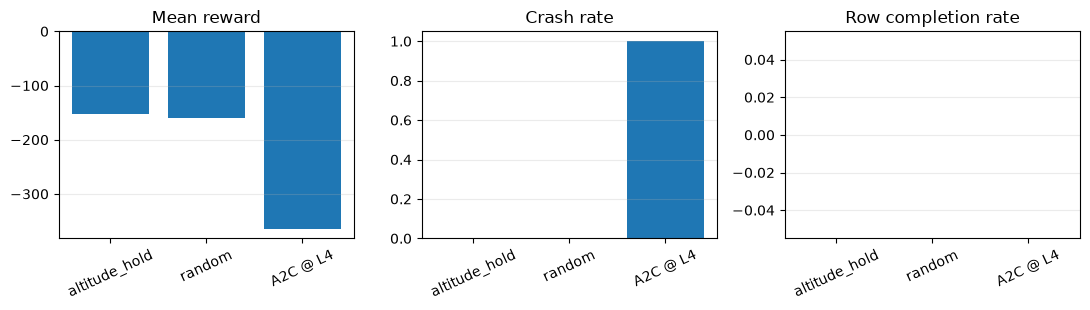

results saved to d:\2026\RL\A3\agroflight-rl\results\a2c_25399217_L4_seed2_20261023_190358_675482.json


In [433]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, col, title in zip(axes, ["mean_reward", "crash_rate", "finish_rate"],
                          ["Mean reward", "Crash rate", "Row completion rate"]):
    ax.bar(df.index, df[col])
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

path = save_results(RESULTS)
print("results saved to", path)
if BACKUP_TO_DRIVE:
    backup_to_drive([RESULTS_DIR, CHECKPOINT_DIR])

<a id="reproducibility"></a>

## 6. Reproducibility

In [434]:
import platform
print("python    :", platform.python_version())
print("torch     :", torch.__version__)
print("numpy     :", np.__version__)
print("gymnasium :", gym.__version__)
print("mujoco    :", mujoco.__version__)
print("git commit:", git_commit())
print("train seed:", EXPERIMENT["train_seed"], "| eval seeds:", EXPERIMENT["eval_seeds"][0], "to", EXPERIMENT["eval_seeds"][-1])
print("notebook wall-clock so far: %.0f s" % (time.time() - NOTEBOOK_T0))

python    : 3.14.7
torch     : 2.14.0+cpu
numpy     : 2.5.3
gymnasium : 1.3.0
mujoco    : 3.14.0
git commit: 08f341b
train seed: 2 | eval seeds: 1000 to 1019
notebook wall-clock so far: 875 s


### References

1. Mnih, V. et al. (2016). Asynchronous Methods for Deep Reinforcement Learning. ICML. arXiv:1602.01783.
2. Sutton, R. S., Barto, A. G. (2018). Reinforcement Learning: An Introduction, 2nd ed. MIT Press. (Chapter 13, actor-critic methods)
3. Todorov, E., Erez, T., Tassa, Y. (2012). MuJoCo: A physics engine for model-based control. IROS.
4. Google DeepMind. MuJoCo Menagerie: Skydio X2 model (Apache-2.0). github.com/google-deepmind/mujoco_menagerie.
5. Towers, M. et al. (2024). Gymnasium: A Standard Interface for Reinforcement Learning Environments. arXiv:2407.17032.